In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

df= pd.read_csv("heart_disease_uci.csv")
df.head()


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [2]:
print(df.shape)
df.info()

(920, 16)
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [3]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [4]:
df["num"].value_counts()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

## Sütun açıklamaları

| Sütun | Anlamı |
|---|---|
| id | Hasta numarası (modelde kullanılmayacak) |
| age | Yaş |
| sex | Cinsiyet (Male/Female) |
| dataset | Verinin toplandığı yer (Cleveland, Hungary, Switzerland, VA Long Beach) |
| cp | Göğüs ağrısı tipi |
| trestbps | Dinlenme hâlindeki kan basıncı (mm Hg) |
| chol | Kolesterol (mg/dl) |
| fbs | Açlık kan şekeri 120 mg/dl'den yüksek mi? (True/False) |
| restecg | Dinlenme hâlindeki EKG sonucu |
| thalch | Ulaşılan en yüksek kalp atış hızı |
| exang | Egzersizle gelen göğüs ağrısı var mı? (True/False) |
| oldpeak | Egzersizle oluşan ST depresyonu (EKG'deki bir değer) |
| slope | Egzersiz sırasındaki ST eğrisinin eğimi |
| ca | Floroskopiyle görülen ana damar sayısı (0-3) |
| thal | Talasemi test sonucu |
| num | **Sonuç:** 0 = hastalık yok, 1-4 = hastalık var (derecesi) |

In [5]:
df["hastalık"] = (df["num"] > 0).astype(int)
df["hastalık"].value_counts()

hastalık
1    509
0    411
Name: count, dtype: int64

In [6]:
df = df.drop(columns=["id", "num","dataset","ca","thal","slope"])
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,hastalık
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,1
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,0


In [7]:
df["chol"] = df["chol"].replace(0, np.nan)

sayisal = ["trestbps", "chol", "thalch", "oldpeak"]
for sutun in sayisal:
    df[sutun] = df[sutun].fillna(df[sutun].median())


kategorik = ["fbs", "restecg", "exang"]    
for sutun in kategorik:
    df[sutun] = df[sutun].fillna(df[sutun].mode()[0])


df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
hastalık    0
dtype: int64

In [8]:
df_model = pd.get_dummies(df, columns=["sex", "cp", "restecg", "fbs","exang"],
                          drop_first=True, dtype = int)

df_model.head() 

,age,trestbps,chol,thalch,oldpeak,hastalık,sex_Male,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,fbs_True,exang_True
0,63,145.0,233.0,150.0,2.3,0,1,0,0,1,0,0,1,0
1,67,160.0,286.0,108.0,1.5,1,1,0,0,0,0,0,0,1
2,67,120.0,229.0,129.0,2.6,1,1,0,0,0,0,0,0,1
3,37,130.0,250.0,187.0,3.5,0,1,0,1,0,1,0,0,0
4,41,130.0,204.0,172.0,1.4,0,0,1,0,0,0,0,0,0


## Veri hakkında gözlemler
1- Veri 920 hasta ve 16 sütun içeriyor.
2- 411 kişi sağlıklı, geriye kalan 509 kişi hasta. Sınıflar %45'e %55 olarak yaklaşık dengeli.
3- ca, thal ve slope sütunlarında çok fazla eksik değer olduğu ve bu değerleri tahminle doldurulamayacağı için sildim.
4- Kolestrol 0 görünen hastalarda böyle bir durum söz konusu olamayacağı için eksik değer olarak kabul ettim.

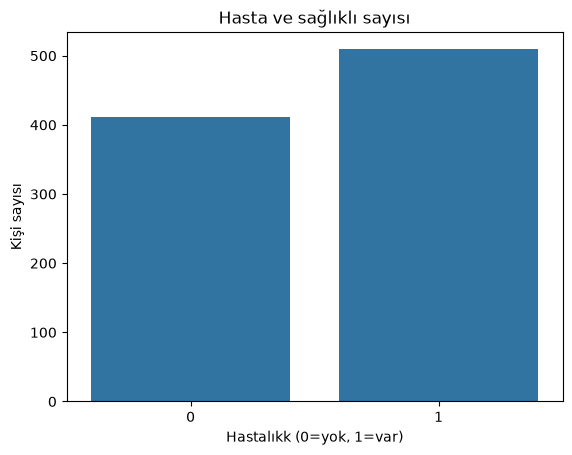

In [9]:
sns.countplot(x="hastalık", data=df)
plt.title("Hasta ve sağlıklı sayısı")
plt.xlabel("Hastalıkk (0=yok, 1=var)")
plt.ylabel("Kişi sayısı")
plt.show()

Grafiğin yorumu: 509 kişide kalp hastalığı var, 411 kişide yok (yaklaşık %55 ve %45). İki grup birbirine yakın olduğu için sınıflar dengeli; bu sayede model tek bir sınıfı ezberleyerek yüksek başarı elde etmiş gibi görünemez.

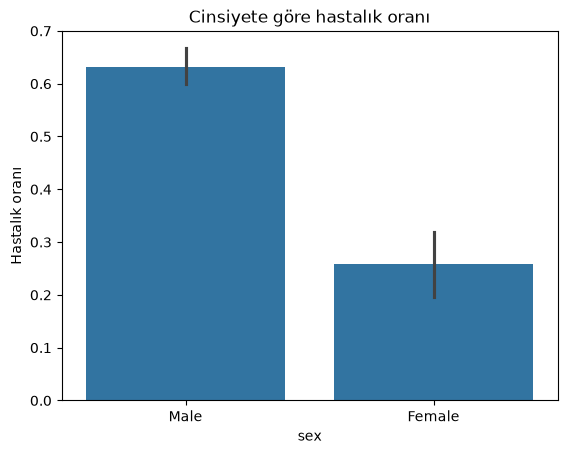

In [10]:
sns.barplot(x="sex", y="hastalık", data=df)
plt.title("Cinsiyete göre hastalık oranı")
plt.ylabel("Hastalık oranı")
plt.show()

Grafik yorumu: Erkeklerde hasta olma ihtimali daha fazla. Kadınların verisi az.

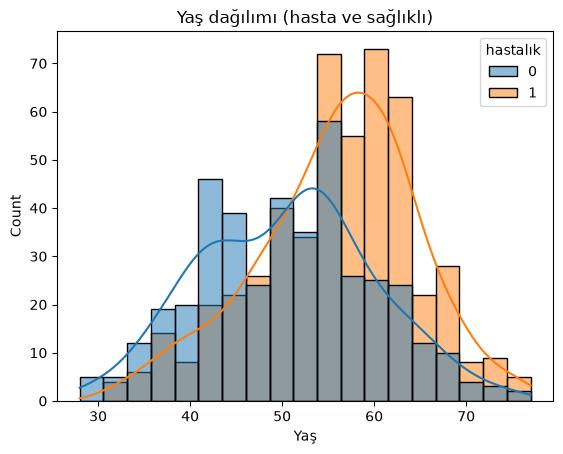

In [11]:
sns.histplot(data=df , x="age", hue="hastalık", kde=True)
plt.title("Yaş dağılımı (hasta ve sağlıklı)")
plt.xlabel("Yaş")
plt.show()

Grafiğin yorumu: Hastaların ağırlıklı olarak 55-65 yaş aralığında, sağlıklı olanların 40-45 yaş aralığında yoğunlaştığını görüyoruz. Yaş ilerledikçe hastalık riski artıyor.

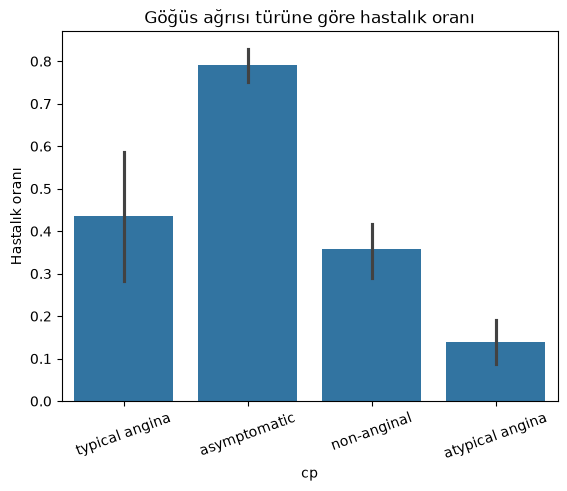

In [12]:
sns.barplot(x="cp", y="hastalık", data=df)
plt.title("Göğüs ağrısı türüne göre hastalık oranı")
plt.xticks(rotation=20)
plt.ylabel("Hastalık oranı")
plt.show()

Grafik yorumu: Göğüs ağrısı olmayanların hastalık oranı en çok çıktı. Beklenmedik bir sonuç.

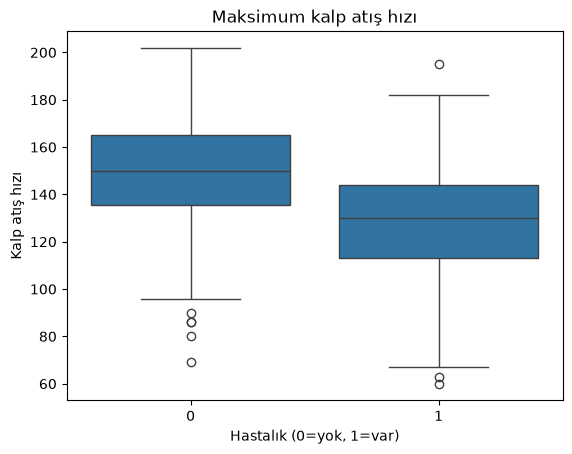

In [13]:
sns.boxplot(x="hastalık", y="thalch", data=df)
plt.title("Maksimum kalp atış hızı")
plt.xlabel("Hastalık (0=yok, 1=var)")
plt.ylabel("Kalp atış hızı")
plt.show()

Grafik yorumu: Hastaların kalp atış hızı egzersiz sırasında daha düşük. Sağlıklı bir kalp egzersiz sırasında daha fazla kalp atış hızlarına çıkabilir.

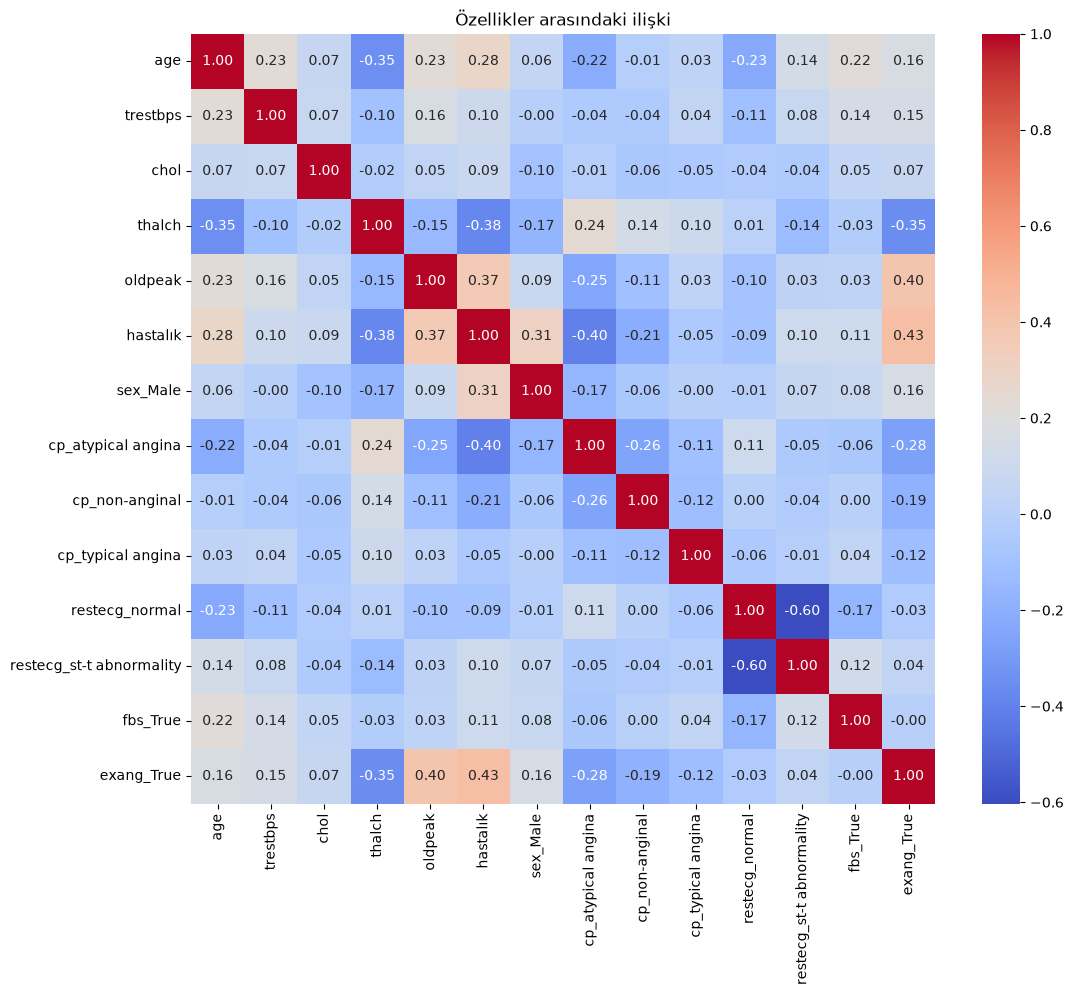

In [14]:
plt.figure(figsize=(12,10))
sns.heatmap(df_model.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Özellikler arasındaki ilişki")
plt.show()

Grafik yorumu:Hastalık en güçlü ilişkiyi exang_true(efor testinde göğüs ağrısı) özelliğiyle kuruyor. En güçlü negatif ilişki ise cp_atypical angina özelliğinde.

## Model

In [15]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns = ["hastalık"])
y = df_model["hastalık"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Eğitim:", X_train.shape, "Test:", X_test.shape)

Eğitim: (736, 13) Test: (184, 13)


In [16]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
lr_tahmin = lr.predict(X_test)

In [17]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
dt_tahmin = dt.predict(X_test)

## Sonuçlar

              precision    recall  f1-score   support

           0       0.81      0.72      0.76        82
           1       0.79      0.86      0.83       102

    accuracy                           0.80       184
   macro avg       0.80      0.79      0.79       184
weighted avg       0.80      0.80      0.80       184



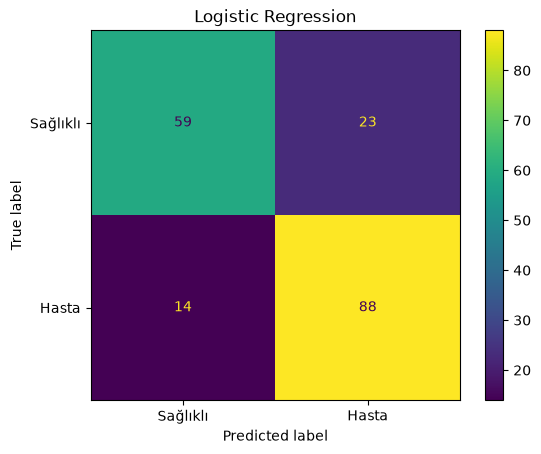

In [18]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(classification_report(y_test, lr_tahmin))

ConfusionMatrixDisplay.from_predictions(y_test, lr_tahmin,
                                        display_labels=["Sağlıklı","Hasta"])
plt.title("Logistic Regression")
plt.show()

              precision    recall  f1-score   support

           0       0.74      0.78      0.76        82
           1       0.82      0.78      0.80       102

    accuracy                           0.78       184
   macro avg       0.78      0.78      0.78       184
weighted avg       0.78      0.78      0.78       184



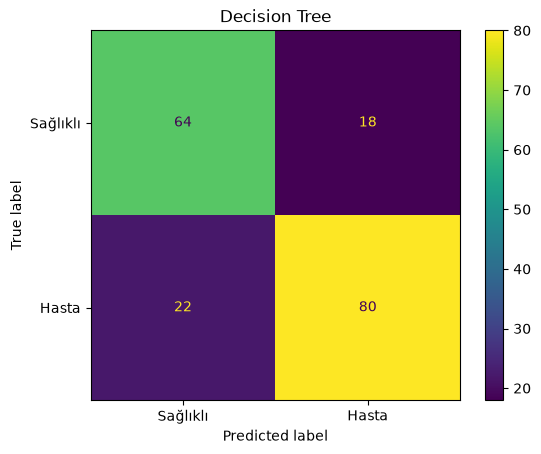

In [19]:
print(classification_report(y_test, dt_tahmin))

ConfusionMatrixDisplay.from_predictions(y_test, dt_tahmin, display_labels=["Sağlıklı","Hasta"])

plt.title("Decision Tree")
plt.show()

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

karsilastirma = pd.DataFrame({
    "Model" : ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(y_test, lr_tahmin), accuracy_score(y_test, dt_tahmin)],
    "Precision": [precision_score(y_test, lr_tahmin), precision_score(y_test, dt_tahmin)],
    "Recall": [recall_score(y_test, lr_tahmin), recall_score(y_test, dt_tahmin)],
})

karsilastirma.round(2)

,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.80,0.79,0.86
1,Decision Tree,0.78,0.82,0.78


**Sonuç ve yorum:**
- Model, 736 hastadan öğrendikten sonra daha önce görmediği 184 hasta üzerinde test edildi.
- Logistic Regression %80 doğrulukla çalıştı ve gerçek hastaların %86'sını yakaladı (102 hastadan 88'i); 14 hastayı kaçırdı, 23 sağlıklı kişiye ise yanlışlıkla "hasta" dedi.
- Decision Tree daha az boşuna alarm verdi (18) ama daha fazla hasta kaçırdı (22).
- Kalp hastalığında bir hastayı kaçırmanın (yanlış "hayır") maliyeti, sağlıklı birine fazladan test yaptırmaktan (yanlış "evet") çok daha yüksek. Bu yüzden en önemli ölçü recall, ve recall'u daha yüksek olan Logistic Regression'ı seçiyorum.